<a href="https://colab.research.google.com/github/UnnimayaVAshok/my_projects/blob/main/height_weight.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
data = pd.read_csv("data.csv")
df = pd.DataFrame(data)
df

,Height,Weight
0,1.47,52.21
1,1.50,53.12
2,1.52,54.48
3,1.55,55.84
4,1.57,57.20
5,1.60,58.57
6,1.63,59.93
7,1.65,61.29
8,1.68,63.11
9,1.70,64.47


In [ ]:
df.head()

,Height,Weight
0,1.47,52.21
1,1.50,53.12
2,1.52,54.48
3,1.55,55.84
4,1.57,57.20


In [ ]:
df.tail()

,Height,Weight
10,1.73,66.28
11,1.75,68.10
12,1.78,69.92
13,1.80,72.19
14,1.83,74.46


In [ ]:
df.shape

(15, 2)

In [ ]:
df.columns

Index(['Height', 'Weight'], dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Height  15 non-null     float64
 1   Weight  15 non-null     float64
dtypes: float64(2)
memory usage: 372.0 bytes


In [ ]:
df.describe()

,Height,Weight
count,15.000000,15.000000
mean,1.650667,62.078000
std,0.114235,7.037515
min,1.470000,52.210000
25%,1.560000,56.520000
50%,1.650000,61.290000
75%,1.740000,67.190000
max,1.830000,74.460000


In [ ]:
df.isna().sum()

,0
Height,0
Weight,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
X = df.iloc[:,:-1]
y = df.iloc[:,-1]
X

,Height
0,1.47
1,1.50
2,1.52
3,1.55
4,1.57
5,1.60
6,1.63
7,1.65
8,1.68
9,1.70


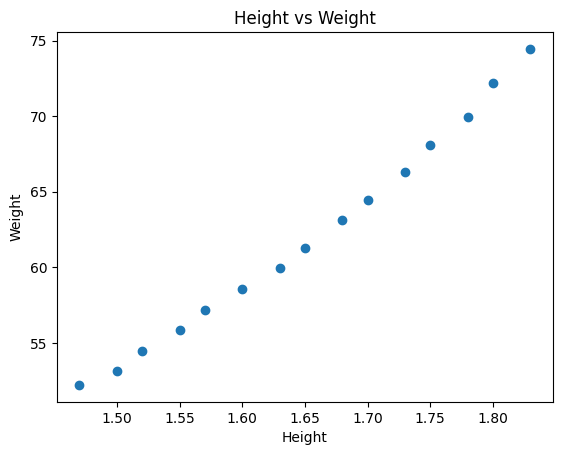

In [ ]:
plt.scatter(X,y)
plt.title("Height vs Weight")
plt.xlabel("Height")
plt.ylabel("Weight")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=42)

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train,y_train)
y_pred = model.predict(X_test)
y_pred

array([65.03579687, 68.13650836, 50.77252401, 71.23721985, 58.83437389])

In [ ]:
print(model.predict(scaler.transform([[1.66]])))

[62.55522768]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


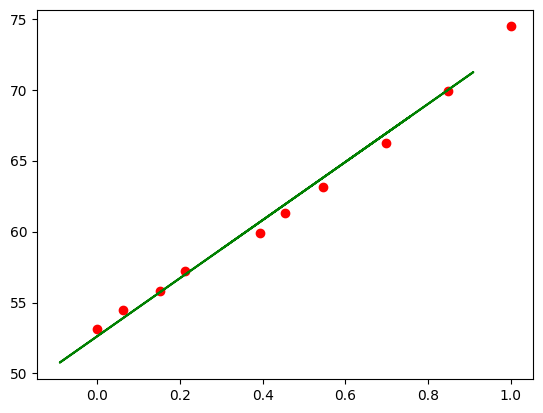

In [ ]:
plt.scatter(X_train,y_train,color="r")
plt.plot(X_test,y_pred,color="g")

In [ ]:
print(model.coef_)

[20.46469584]


In [ ]:
print(model.intercept_)

52.63295090715049


In [ ]:
diff = y_test - y_pred
df_1 = pd.DataFrame({"Actual_value":y_test,"Predicted_value":y_pred,"Difference":y_test - y_pred}).reset_index(drop=True)
df_1

,Actual_value,Predicted_value,Difference
0,64.47,65.035797,-0.565797
1,68.10,68.136508,-0.036508
2,52.21,50.772524,1.437476
3,72.19,71.237220,0.952780
4,58.57,58.834374,-0.264374


In [ ]:
from sklearn.metrics import mean_absolute_error

MAE = mean_absolute_error(y_test,y_pred)
print(MAE)

0.6513870508715698


In [ ]:
from sklearn.metrics import mean_absolute_percentage_error

MAPE = mean_absolute_percentage_error(y_test,y_pred)
print(MAPE)

0.010911368997744732


In [ ]:
from sklearn.metrics import mean_squared_error

MSE = mean_squared_error(y_test,y_pred)
print(MSE)

0.6730959475011741


In [ ]:
from sklearn.metrics import root_mean_squared_error

RMSE = root_mean_squared_error(y_test,y_pred)
print(RMSE)

0.8204242484843888


In [ ]:
from sklearn.metrics import r2_score

score = r2_score(y_test,y_pred)
print(score)

0.9864632324720194
